# Minimal article serving: GoRun, WordPress and Astro

## tl;dr
At a target of 50 requests/s, all deployments issued about 50 requests/s. Median run p95 latency was **2.66 ms for GoRun**, **16.85 ms for WordPress + MariaDB**, and **0.66 ms for Astro static + Nginx**. These are three repeated synthetic tests on one disposable host, not production CMS rankings.

At the 200 target the WordPress test issued only about 92 requests/s: that comparison has unequal delivered load. **GoRun Edge has no runnable CMS and is not measured.**

## Context & Methods
100 identical synthetic articles, each response 4,513 bytes. Minimal templates, no TLS/CDN/full-page cache/plugins. WordPress 7.1.3 + MariaDB 11.4; Astro 7.4.0 output served by Nginx. GoRun built from the recorded repository checkout; its version string is `benchmark`, not a released UI build. Exact commit, image identities and dependency lockfile are retained in raw data.

### Key assumptions and limits
- Two logical server CPUs (SMT siblings of one physical core), 2 GiB total budget per deployment. WordPress includes its database. Other logical CPUs run the load generator.
- Three rotated repetitions, each with 5-second warmup and 30-second targets of 50 then 200 requests/s. Target order is fixed, so these are not independent cold-start measurements.
- Vegeta installation is pinned to 12.13.0 in the workflow; its embedded version fields are blank. The 100-worker limit throttles issued traffic when latency grows. Achieved throughput is not maximum capacity.
- Per-run p95 is summarized by median and observed min–max, not pooled percentiles or confidence intervals. Memory is sampled aggregate Docker working set, not process RSS or total host memory.
- PHP version/INI were queried through CLI. Apache SAPI opcache behavior was not independently verified. This is not a tuned WordPress comparison.
- No end-to-end installation time, editorial work, browser rendering, provider generation, cache tuning or public network performance is measured.

[Original workflow run](https://github.com/zadstack/gorun/actions/runs/39233436452). The full raw artifact is preserved beside this notebook as `raw.tar.gz` with SHA-256.

## Data
### 1. Verify and load the preserved evidence
The standard-library analyzer rejects incomplete/duplicate runs, missing samples, fixture mismatches, inconsistent HTTP totals and failed rate reconciliation. Files below are extracted only from the checked-in artifact; no network or credentials are used.

In [1]:
from pathlib import Path
import hashlib, json, sys, tarfile, tempfile
from IPython.display import display, Markdown, Image
here = Path.cwd()
archive = here / 'raw.tar.gz'
expected = (here / 'SHA256SUMS').read_text().split()[0]
assert hashlib.sha256(archive.read_bytes()).hexdigest() == expected
scratch = tempfile.TemporaryDirectory(prefix='gorun-analysis-')
source = Path(scratch.name)
with tarfile.open(archive, 'r:gz') as package:
    package.extractall(source, filter='data')
sys.path.insert(0, str(here.parents[1]))
from analyze import analyze, table
summary = analyze(source)
metadata = json.loads((source / 'metadata.json').read_text())
assert len(summary['rows']) == 18
print('Validated: 18 distinct runs, 100 fixture URLs per product, all recorded HTTP responses successful.')
print('Measured checkout:', metadata['commit'])
print('Measurement started (UTC):', metadata['utc'])
print('Fixture SHA-256:', metadata['fixture_sha256'])

Validated: 18 distinct runs, 100 fixture URLs per product, all recorded HTTP responses successful.
Measured checkout: 44e44ba4abcd64773ea0fb042062848dbeb62415
Measurement started (UTC): 2026-10-19T09:54:01Z
Fixture SHA-256: 877c51cc7624887bf4a7740fa2924de205e834a9faca9540ce6f01e5af62bfb8


## Results
### 2. Compare the equal-rate condition
Values are median (minimum–maximum) over three repetitions. Peak working set includes the WordPress database.

In [2]:
display(Markdown(table(summary, 50)))

| Deployment | Issued req/s | Successful req/s | p95 latency, ms | Peak working set, MiB |
| --- | ---: | ---: | ---: | ---: |
| GoRun | 50.03 (50.03–50.03) | 50.03 (50.03–50.03) | 2.66 (2.66–2.71) | 114.54 (114.40–116.13) |
| WordPress + MariaDB | 50.03 (50.03–50.03) | 50.01 (50.01–50.01) | 16.85 (16.54–17.02) | 203.78 (203.45–204.39) |
| Astro static + Nginx | 50.03 (50.03–50.03) | 50.03 (50.03–50.03) | 0.66 (0.61–0.66) | 4.09 (3.95–4.09) |

### 3. Inspect latency and resource use
Dots show each repetition; the central marker and line show median and observed range. All panels start at zero. These ranges describe three observations, not uncertainty intervals.

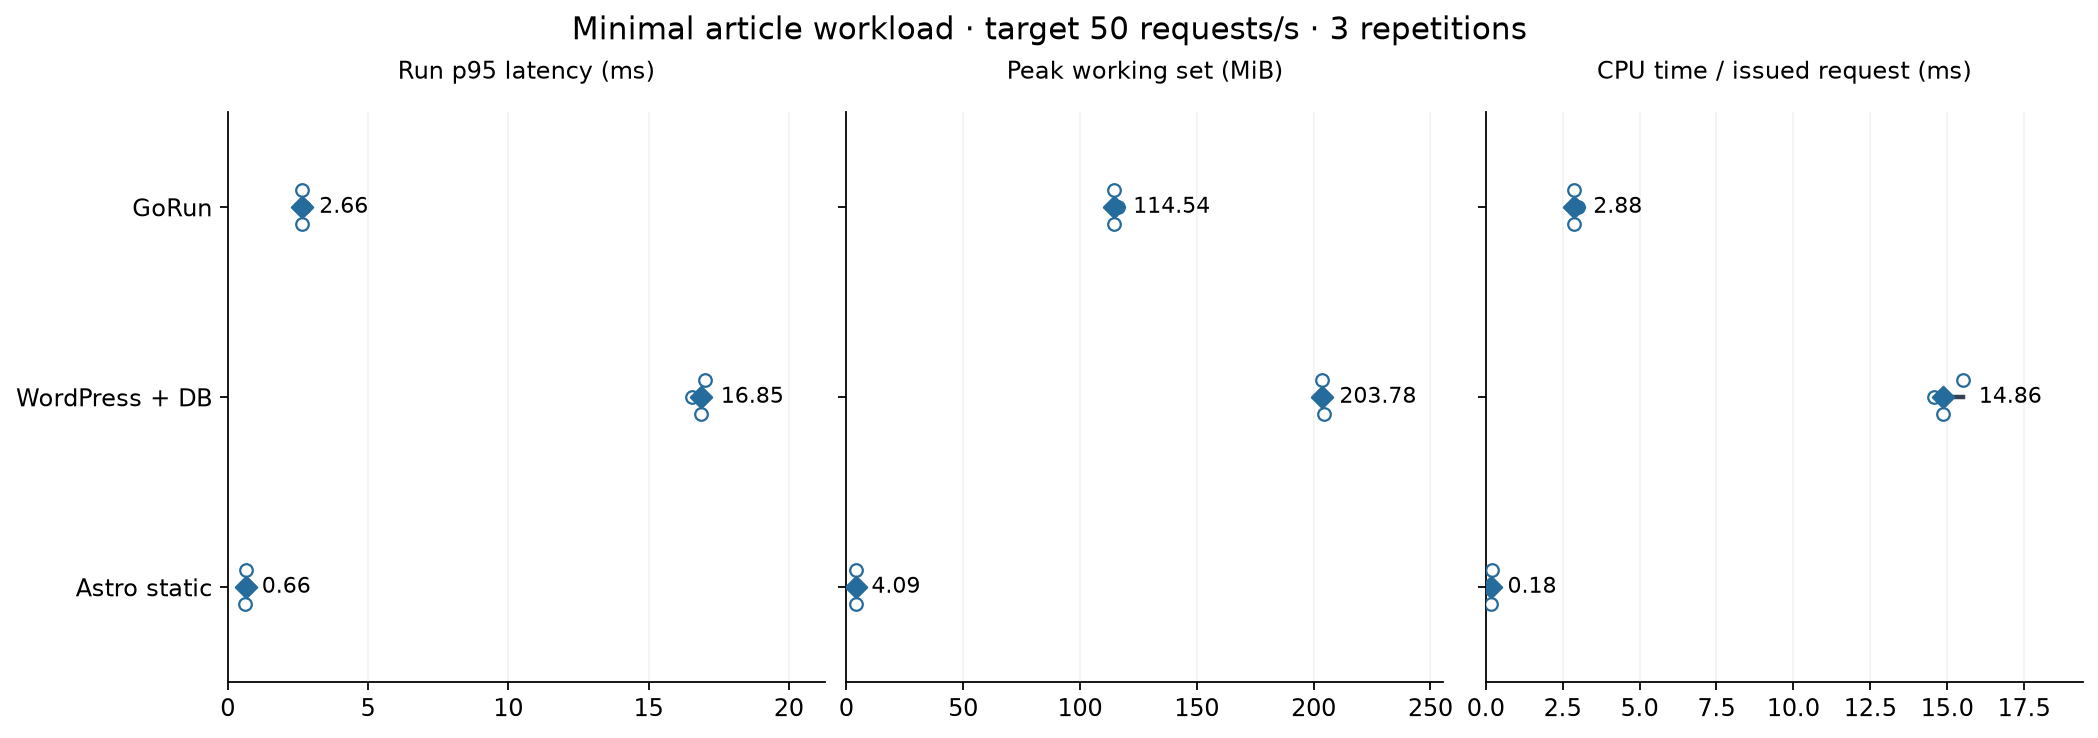

In [3]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from statistics import median
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
products = ['gorun','wordpress','astro-static']
labels = ['GoRun','WordPress + DB','Astro static']
fig, axes = plt.subplots(1,3,figsize=(13,4.5), layout='constrained')
for ax, metric, title in zip(axes, ['p95_ms','peak_working_set_mib','cpu_ms_per_request'], ['Run p95 latency (ms)','Peak working set (MiB)','CPU time / issued request (ms)']):
    for y, product in enumerate(products):
        values = [r[metric] for r in summary['rows'] if r['product']==product and r['target_rps']==50]
        middle = median(values)
        ax.plot([min(values),max(values)],[y,y],color='#344054',linewidth=2)
        ax.scatter(values,[y-.09,y,y+.09],s=32,facecolors='white',edgecolors='#256b9b',zorder=3)
        ax.scatter([middle],[y],s=46,c='#256b9b',marker='D',zorder=4)
        ax.annotate(f'{middle:.2f}',(max(values),y),xytext=(7,0),textcoords='offset points',va='center',fontsize=10)
    ax.set_yticks(range(3),labels if ax is axes[0] else [])
    ax.set_ylim(2.5,-.5)
    ax.set_xlim(0,max(r[metric] for r in summary['rows'] if r['target_rps']==50)*1.25)
    ax.set_title(title,fontsize=11,pad=15)
    ax.grid(axis='x',alpha=.15)
fig.suptitle('Minimal article workload · target 50 requests/s · 3 repetitions',fontsize=14)
fig.savefig(here/'comparison-50rps.png',dpi=160,bbox_inches='tight')
display(Image(filename=str(here/'comparison-50rps.png')))
plt.close(fig)

### 4. Keep target and delivered traffic separate
The WordPress 200-target condition did not expose it to 200 issued requests/s. Its latency and throughput here cannot establish a matched-load comparison or maximum server capacity.

In [4]:
display(Markdown(table(summary, 200)))

| Deployment | Issued req/s | Successful req/s | p95 latency, ms | Peak working set, MiB |
| --- | ---: | ---: | ---: | ---: |
| GoRun | 200.03 (200.03–200.03) | 200.02 (200.02–200.02) | 2.61 (2.55–2.80) | 117.38 (117.11–117.40) |
| WordPress + MariaDB | 91.74 (91.54–96.26) | 90.24 (90.10–94.67) | 1208.95 (1157.52–1244.49) | 779.48 (779.10–780.86) |
| Astro static + Nginx | 200.03 (200.03–200.04) | 200.03 (200.03–200.03) | 0.44 (0.40–0.45) | 4.08 (3.96–4.15) |

## Takeaways
GoRun recorded lower latency and sampled memory than this uncached WordPress deployment under the equal-rate minimal article workload. The static Astro reference recorded the lowest latency and memory; it does not include a CMS editor or database.

The practical differentiators require their own product evidence: local setup, editorial controls, Arabic/English UI and bounded agent workflows. These serving measurements do not establish feature superiority, security superiority, production capacity or install-time claims. Edge remains **unavailable**, never zero.

Rerun from this folder with Python 3.12+, `nbclient`, `nbformat`, `ipykernel`, `matplotlib`, and `nbconvert`; the calculation-only alternative is `python3 ../../analyze.py <extracted-raw-directory> --output <new-directory>`.